In [1]:
import pandas as pd
import numpy as np

raw = pd.read_csv('../Dataset/raw_dataset/WDI-1.csv')
print(raw.shape)
raw.head()

(1045, 14)


,Country Name,Country Code,Series Name,Series Code,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Argentina,ARG,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,58.79,55.022,49.926,41.751,31.492,28.54,25.767,26.414,25.56,..
1,Argentina,ARG,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,6.2645658204639,5.23162237679509,4.53787889696835,5.31855599661392,6.35703367590492,7.29128249619051,6.5415694049027,5.8467786039042,5.80601710916249,5.53265388071299
2,Argentina,ARG,"Annual freshwater withdrawals, total (% of int...",ER.H2O.FWTL.ZS,12.9075342465753,12.9075342465753,12.9075342465753,12.9075342465753,12.9075342465753,12.9075342465753,12.9075342465753,..,..,..
3,Argentina,ARG,Births attended by skilled health staff (% of ...,SH.STA.BRTC.ZS,98.4,93.9,99.5,99.6,98.8,..,..,..,..,..
4,Argentina,ARG,"Contraceptive prevalence, any method (% of mar...",SP.DYN.CONU.ZS,..,..,..,..,70.1027087175867,..,..,..,..,..


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Country Name   1042 non-null   str  
 1   Country Code   1040 non-null   str  
 2   Series Name    1040 non-null   str  
 3   Series Code    1040 non-null   str  
 4   2016 [YR2016]  1040 non-null   str  
 5   2017 [YR2017]  1040 non-null   str  
 6   2018 [YR2018]  1040 non-null   str  
 7   2019 [YR2019]  1040 non-null   str  
 8   2020 [YR2020]  1040 non-null   str  
 9   2021 [YR2021]  1040 non-null   str  
 10  2022 [YR2022]  1040 non-null   str  
 11  2023 [YR2023]  1040 non-null   str  
 12  2024 [YR2024]  1040 non-null   str  
 13  2025 [YR2025]  1040 non-null   str  
dtypes: str(14)
memory usage: 114.4 KB


In [3]:
raw_df = raw.copy()
clean_df = raw.copy()

In [4]:
clean_df.isnull().sum()

Country Name     3
Country Code     5
Series Name      5
Series Code      5
2016 [YR2016]    5
2017 [YR2017]    5
2018 [YR2018]    5
2019 [YR2019]    5
2020 [YR2020]    5
2021 [YR2021]    5
2022 [YR2022]    5
2023 [YR2023]    5
2024 [YR2024]    5
2025 [YR2025]    5
dtype: int64

In [5]:
year_cols = [c for c in clean_df.columns if 'YR' in c]
(clean_df[year_cols] == '..').sum()

2016 [YR2016]    123
2017 [YR2017]    126
2018 [YR2018]    121
2019 [YR2019]    128
2020 [YR2020]    132
2021 [YR2021]    161
2022 [YR2022]    177
2023 [YR2023]    220
2024 [YR2024]    326
2025 [YR2025]    642
dtype: int64

In [6]:
clean_df = clean_df.dropna(subset=['Country Code'])
print(clean_df.shape)
clean_df.isnull().sum()

(1040, 14)


Country Name     0
Country Code     0
Series Name      0
Series Code      0
2016 [YR2016]    0
2017 [YR2017]    0
2018 [YR2018]    0
2019 [YR2019]    0
2020 [YR2020]    0
2021 [YR2021]    0
2022 [YR2022]    0
2023 [YR2023]    0
2024 [YR2024]    0
2025 [YR2025]    0
dtype: int64

In [7]:
clean_df = clean_df.replace('..', np.nan)

year_cols = [c for c in clean_df.columns if 'YR' in c]
clean_df[year_cols] = clean_df[year_cols].apply(pd.to_numeric, errors='coerce')

clean_df[year_cols].dtypes

2016 [YR2016]    float64
2017 [YR2017]    float64
2018 [YR2018]    float64
2019 [YR2019]    float64
2020 [YR2020]    float64
2021 [YR2021]    float64
2022 [YR2022]    float64
2023 [YR2023]    float64
2024 [YR2024]    float64
2025 [YR2025]    float64
dtype: object

In [8]:
clean_df[year_cols].isnull().sum()

2016 [YR2016]    123
2017 [YR2017]    126
2018 [YR2018]    121
2019 [YR2019]    128
2020 [YR2020]    132
2021 [YR2021]    161
2022 [YR2022]    177
2023 [YR2023]    220
2024 [YR2024]    326
2025 [YR2025]    642
dtype: int64

In [9]:
clean_df.columns = [c.split(' [')[0] for c in clean_df.columns]

clean_df = clean_df.rename(columns={
    'Country Name': 'Country',
    'Country Code': 'Country_Code',
    'Series Name': 'Indicator',
    'Series Code': 'Indicator_Code'
})

clean_df.columns.tolist()

['Country',
 'Country_Code',
 'Indicator',
 'Indicator_Code',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025']

In [10]:
clean_df.head()

,Country,Country_Code,Indicator,Indicator_Code,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Argentina,ARG,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,58.790000,55.022000,49.926000,41.751000,31.492000,28.540000,25.767000,26.414000,25.560000,NaN
1,Argentina,ARG,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,6.264566,5.231622,4.537879,5.318556,6.357034,7.291282,6.541569,5.846779,5.806017,5.532654
2,Argentina,ARG,"Annual freshwater withdrawals, total (% of int...",ER.H2O.FWTL.ZS,12.907534,12.907534,12.907534,12.907534,12.907534,12.907534,12.907534,NaN,NaN,NaN
3,Argentina,ARG,Births attended by skilled health staff (% of ...,SH.STA.BRTC.ZS,98.400000,93.900000,99.500000,99.600000,98.800000,NaN,NaN,NaN,NaN,NaN
4,Argentina,ARG,"Contraceptive prevalence, any method (% of mar...",SP.DYN.CONU.ZS,NaN,NaN,NaN,NaN,70.102709,NaN,NaN,NaN,NaN,NaN


In [12]:
#Reshape the table from wide to long
years = [c for c in clean_df.columns if c.isdigit()]

long_df = clean_df.melt(
    id_vars=['Country', 'Country_Code', 'Indicator', 'Indicator_Code'],
    value_vars=years,
    var_name='Year',
    value_name='Value'
)

long_df['Year'] = long_df['Year'].astype(int)

print(long_df.shape)
long_df.head()

(10400, 6)


,Country,Country_Code,Indicator,Indicator_Code,Year,Value
0,Argentina,ARG,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,2016,58.790000
1,Argentina,ARG,"Agriculture, forestry, and fishing, value adde...",NV.AGR.TOTL.ZS,2016,6.264566
2,Argentina,ARG,"Annual freshwater withdrawals, total (% of int...",ER.H2O.FWTL.ZS,2016,12.907534
3,Argentina,ARG,Births attended by skilled health staff (% of ...,SH.STA.BRTC.ZS,2016,98.400000
4,Argentina,ARG,"Contraceptive prevalence, any method (% of mar...",SP.DYN.CONU.ZS,2016,NaN


In [13]:
#Check for duplicates and save the cleaned file
print('Duplicate rows:', long_df.duplicated().sum())
long_df = long_df.drop_duplicates().reset_index(drop=True)

print('Countries :', long_df['Country'].nunique())
print('Indicators:', long_df['Indicator'].nunique())
print('Years     :', long_df['Year'].min(), '-', long_df['Year'].max())
print('Missing % :', round(long_df['Value'].isna().mean() * 100, 1))

Duplicate rows: 0
Countries : 20
Indicators: 52
Years     : 2016 - 2025
Missing % : 20.7


In [14]:
raw_df.to_csv('../Dataset/raw_dataset.csv', index=False)
long_df.to_csv('../Dataset/cleaned_dataset.csv', index=False)
print('Saved both files')

Saved both files


In [16]:
#Build the analysis table (one row per country and year)
short_names = {
    'GDP (current US$)': 'GDP_USD',
    'GDP growth (annual %)': 'GDP_Growth_Pct',
    'GNI per capita, Atlas method (current US$)': 'GNI_Per_Capita',
    'Population, total': 'Population',
    'Population growth (annual %)': 'Population_Growth_Pct',
    'Life expectancy at birth, total (years)': 'Life_Expectancy',
    'Fertility rate, total (births per woman)': 'Fertility_Rate',
    'Mortality rate, under-5 (per 1,000 live births)': 'Under5_Mortality',
    'Exports of goods and services (% of GDP)': 'Exports_Pct_GDP',
    'Imports of goods and services (% of GDP)': 'Imports_Pct_GDP',
    'Inflation, GDP deflator (annual %)': 'Inflation_Pct',
    'Military expenditure (% of GDP)': 'Military_Exp_Pct_GDP',
    'Mobile cellular subscriptions (per 100 people)': 'Mobile_Subs_Per100',
    'Industry (including construction), value added (% of GDP)': 'Industry_Pct_GDP',
    'Agriculture, forestry, and fishing, value added (% of GDP)': 'Agriculture_Pct_GDP',
    'Gross capital formation (% of GDP)': 'Capital_Formation_Pct_GDP',
}

df = long_df.copy()
df['Short'] = df['Indicator'].map(short_names)
df = df.dropna(subset=['Short'])

panel = df.pivot_table(index=['Country', 'Country_Code', 'Year'],
                       columns='Short', values='Value').reset_index()
panel.columns.name = None

print(panel.shape)
panel.head()

(200, 19)


,Country,Country_Code,Year,Agriculture_Pct_GDP,Capital_Formation_Pct_GDP,Exports_Pct_GDP,Fertility_Rate,GDP_Growth_Pct,GDP_USD,GNI_Per_Capita,Imports_Pct_GDP,Industry_Pct_GDP,Inflation_Pct,Life_Expectancy,Military_Exp_Pct_GDP,Mobile_Subs_Per100,Population,Population_Growth_Pct,Under5_Mortality
0,Argentina,ARG,2016,6.264566,17.663228,12.527095,2.241,-2.080328,5.575323e+11,12130.0,13.566793,22.054107,41.119380,76.105,0.809245,145.146585,43900313.0,0.968911,11.4
1,Argentina,ARG,2017,5.231622,18.212567,11.320283,2.168,2.818503,6.436284e+11,13070.0,13.969318,21.782123,26.006379,76.543,0.847755,139.758241,44288894.0,0.881250,11.0
2,Argentina,ARG,2018,4.537879,16.613885,14.436686,2.067,-2.617396,5.248199e+11,12390.0,16.325850,23.719592,42.033669,76.770,0.732300,131.224266,44654882.0,0.822969,10.7
3,Argentina,ARG,2019,5.318556,14.210030,17.924878,1.882,-2.000861,4.477547e+11,11210.0,14.705737,23.157848,49.195579,76.847,0.699696,125.302658,44973465.0,0.710901,10.5
4,Argentina,ARG,2020,6.357034,14.415156,16.605414,1.601,-9.900485,3.857405e+11,9040.0,13.598284,22.408876,40.083088,75.878,0.734112,121.180613,45191965.0,0.484666,10.3


In [17]:
#Missing values and summary statistics for the analysis table
panel.isnull().sum().sort_values(ascending=False)

Mobile_Subs_Per100           22
Fertility_Rate               20
Military_Exp_Pct_GDP         20
Life_Expectancy              20
Under5_Mortality             20
Industry_Pct_GDP              5
Agriculture_Pct_GDP           5
Capital_Formation_Pct_GDP     3
Exports_Pct_GDP               2
Imports_Pct_GDP               2
Country                       0
Year                          0
Country_Code                  0
GDP_Growth_Pct                0
GDP_USD                       0
GNI_Per_Capita                0
Inflation_Pct                 0
Population                    0
Population_Growth_Pct         0
dtype: int64

In [18]:
panel.drop(columns='Year').describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Agriculture_Pct_GDP,195.0,4.080000e+00,4.260000e+00,5.600000e-01,1.420000e+00,2.470000e+00,5.730000e+00,1.867000e+01
Capital_Formation_Pct_GDP,197.0,2.510000e+01,6.400000e+00,1.421000e+01,2.091000e+01,2.328000e+01,2.975000e+01,4.331000e+01
Exports_Pct_GDP,198.0,3.209000e+01,1.778000e+01,1.012000e+01,1.948000e+01,2.934000e+01,3.705000e+01,9.644000e+01
Fertility_Rate,180.0,1.640000e+00,3.800000e-01,7.200000e-01,1.420000e+00,1.610000e+00,1.880000e+00,2.670000e+00
GDP_Growth_Pct,200.0,2.320000e+00,3.540000e+00,-1.094000e+01,1.060000e+00,2.290000e+00,4.280000e+00,1.200000e+01
GDP_USD,200.0,3.796164e+12,5.781971e+12,3.857405e+11,1.189669e+12,1.811807e+12,3.170764e+12,3.076970e+13
GNI_Per_Capita,200.0,3.325100e+04,2.432912e+04,1.670000e+03,1.073750e+04,3.391000e+04,4.856250e+04,1.103300e+05
Imports_Pct_GDP,198.0,2.991000e+01,1.526000e+01,1.180000e+01,1.855000e+01,2.702000e+01,3.499000e+01,8.766000e+01
Industry_Pct_GDP,195.0,2.681000e+01,7.910000e+00,1.577000e+01,2.013000e+01,2.553000e+01,3.181000e+01,5.312000e+01
Inflation_Pct,200.0,8.180000e+00,2.130000e+01,-1.019000e+01,1.280000e+00,2.990000e+00,5.690000e+00,2.076100e+02


In [19]:
pd.set_option('display.float_format', '{:,.2f}'.format)

country_profile = panel.groupby('Country')[
    ['GNI_Per_Capita', 'GDP_Growth_Pct', 'Inflation_Pct',
     'Life_Expectancy', 'Exports_Pct_GDP']
].mean().sort_values('GNI_Per_Capita', ascending=False)

country_profile

,GNI_Per_Capita,GDP_Growth_Pct,Inflation_Pct,Life_Expectancy,Exports_Pct_GDP
Country,,,,,
Switzerland,"91,634.00",1.87,0.61,83.75,69.28
United States,"70,961.00",2.43,2.87,78.06,11.42
Australia,"57,630.00",2.26,3.18,82.93,23.22
Netherlands,"56,464.00",1.94,3.41,81.71,85.33
Germany,"51,649.00",0.76,3.03,80.94,42.08
United Kingdom,"45,922.00",1.44,3.29,81.07,31.07
France,"43,038.00",1.22,1.89,82.57,32.78
Japan,"41,219.00",0.51,1.43,84.19,18.24
Italy,"36,138.00",1.12,2.06,83.10,31.36


### Q1: Distribution of GDP Growth

In [20]:
growth_category = pd.cut(
    panel['GDP_Growth_Pct'],
    bins=[-np.inf, 0, 2, 4, np.inf],
    labels=['Contraction (<0%)', 'Slow (0-2%)', 'Moderate (2-4%)', 'Strong (>4%)']
)

growth_counts = growth_category.value_counts().reindex(
    ['Contraction (<0%)', 'Slow (0-2%)', 'Moderate (2-4%)', 'Strong (>4%)']
)

growth_percent = (growth_counts / growth_counts.sum()) * 100

growth_summary = pd.DataFrame({
    'Growth Category': growth_counts.index,
    'Number of Country-Years': growth_counts.values,
    'Percentage': growth_percent.values.round(2)
})

growth_summary

,Growth Category,Number of Country-Years,Percentage
0,Contraction (<0%),31,15.50
1,Slow (0-2%),58,29.00
2,Moderate (2-4%),59,29.50
3,Strong (>4%),52,26.00


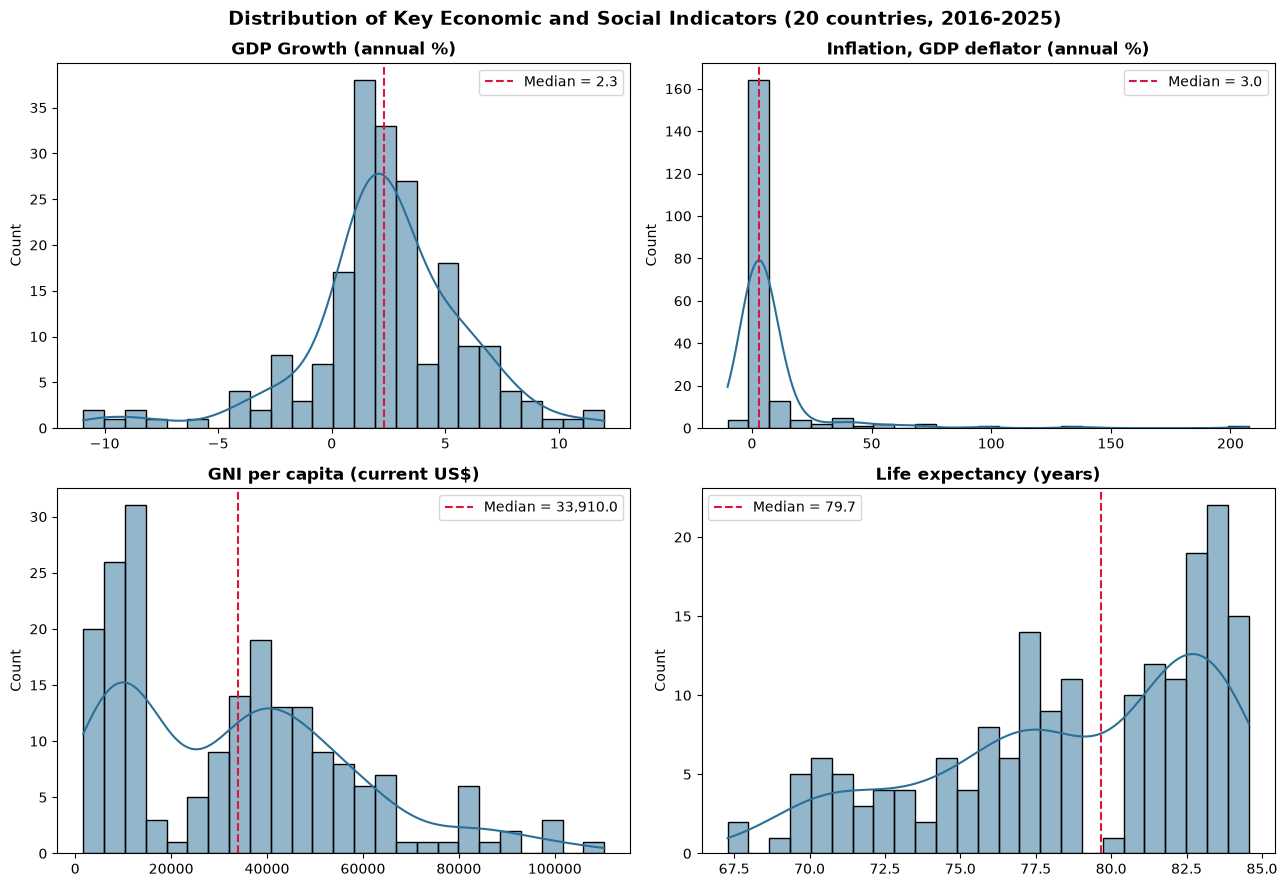

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

indicators = [('GDP_Growth_Pct', 'GDP Growth (annual %)'),
              ('Inflation_Pct', 'Inflation, GDP deflator (annual %)'),
              ('GNI_Per_Capita', 'GNI per capita (current US$)'),
              ('Life_Expectancy', 'Life expectancy (years)')]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (col, title) in zip(axes.ravel(), indicators):
    sns.histplot(panel[col].dropna(), kde=True, bins=25, ax=ax, color='#2a6f97')
    median = panel[col].median()
    ax.axvline(median, color='crimson', linestyle='--', label=f'Median = {median:,.1f}')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')
    ax.legend()

fig.suptitle('Distribution of Key Economic and Social Indicators (20 countries, 2016-2025)',
             fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig('../Visualizations/distribution_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### Q2: Average Profile of Each Country

In [21]:
pd.set_option('display.float_format', '{:,.2f}'.format)

country_profile = panel.groupby('Country')[
    ['GNI_Per_Capita', 'GDP_Growth_Pct', 'Inflation_Pct',
     'Life_Expectancy', 'Exports_Pct_GDP']
].mean().sort_values('GNI_Per_Capita', ascending=False)

country_profile

,GNI_Per_Capita,GDP_Growth_Pct,Inflation_Pct,Life_Expectancy,Exports_Pct_GDP
Country,,,,,
Switzerland,"91,634.00",1.87,0.61,83.75,69.28
United States,"70,961.00",2.43,2.87,78.06,11.42
Australia,"57,630.00",2.26,3.18,82.93,23.22
Netherlands,"56,464.00",1.94,3.41,81.71,85.33
Germany,"51,649.00",0.76,3.03,80.94,42.08
United Kingdom,"45,922.00",1.44,3.29,81.07,31.07
France,"43,038.00",1.22,1.89,82.57,32.78
Japan,"41,219.00",0.51,1.43,84.19,18.24
Italy,"36,138.00",1.12,2.06,83.10,31.36


## Q3 — Trend of GDP Growth Over Time

In [22]:
yearly_growth = panel.groupby('Year')['GDP_Growth_Pct'].agg(['mean', 'min', 'max']).round(2)
yearly_growth.columns = ['Average Growth %', 'Lowest Country %', 'Highest Country %']
yearly_growth

,Average Growth %,Lowest Country %,Highest Country %
Year,,,
2016,2.20,-3.28,8.26
2017,3.10,1.18,7.83
2018,2.60,-2.62,6.76
2019,1.79,-2.00,6.07
2020,-4.32,-10.94,2.34
2021,6.56,2.01,11.81
2022,4.25,-1.44,12.00
2023,2.25,-1.86,7.21
2024,2.29,-1.34,7.10


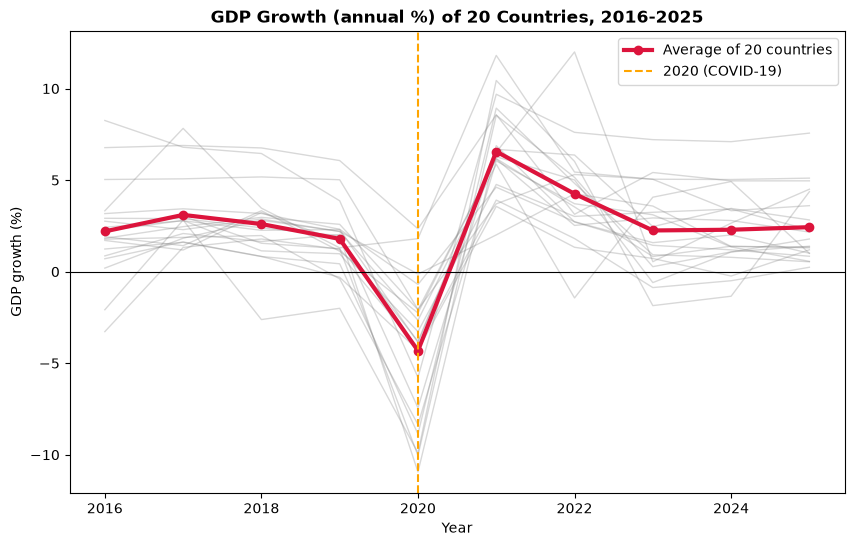

In [23]:
import os
import matplotlib.pyplot as plt

os.makedirs('../Visualizations', exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))

# One faint grey line per country
for country, g in panel.groupby('Country'):
    ax.plot(g['Year'], g['GDP_Growth_Pct'], color='grey', alpha=0.3, linewidth=1)

# Bold red line for the average of all 20 countries
ax.plot(yearly_growth.index, yearly_growth['Average Growth %'],
        color='crimson', linewidth=3, marker='o', label='Average of 20 countries')

ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(2020, color='orange', linestyle='--', label='2020 (COVID-19)')
ax.set_title('GDP Growth (annual %) of 20 Countries, 2016-2025', fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('GDP growth (%)')
ax.legend()

fig.savefig('../Visualizations/trend_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## Q4 — COVID-19 Impact (2019 vs 2020 vs 2021)

In [24]:
covid = panel[panel['Year'].isin([2019, 2020, 2021])].pivot(
    index='Country', columns='Year', values='GDP_Growth_Pct'
)

covid['Change 2019 to 2020'] = covid[2020] - covid[2019]
covid = covid.sort_values('Change 2019 to 2020').round(2)
covid

Year,2019,2020,2021,Change 2019 to 2020
Country,,,,
Spain,1.96,-10.94,6.68,-12.90
United Kingdom,1.26,-10.05,8.54,-11.30
India,3.87,-5.78,9.69,-9.65
France,2.03,-7.44,6.88,-9.47
Italy,0.43,-8.87,8.93,-9.30
Mexico,-0.39,-8.35,6.05,-7.96
Argentina,-2.00,-9.90,10.44,-7.90
Indonesia,5.02,-2.07,3.70,-7.08
Netherlands,2.30,-3.87,6.28,-6.17


## Q5 — Outliers in Inflation and GDP Growth

In [25]:
def find_outliers(data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(f'{col}: lower limit = {lower:.2f}, upper limit = {upper:.2f}')
    out = data[(data[col] < lower) | (data[col] > upper)]
    return out[['Country', 'Year', col]].sort_values(col, ascending=False)

inflation_outliers = find_outliers(panel, 'Inflation_Pct')
print('Number of inflation outliers:', len(inflation_outliers))
inflation_outliers.head(10)

Inflation_Pct: lower limit = -5.34, upper limit = 12.31
Number of inflation outliers: 25


,Country,Year,Inflation_Pct
8,Argentina,2024,207.61
7,Argentina,2023,136.74
176,Turkiye,2022,95.53
6,Argentina,2022,68.99
177,Turkiye,2023,68.28
178,Turkiye,2024,59.28
5,Argentina,2021,53.80
3,Argentina,2019,49.20
2,Argentina,2018,42.03
0,Argentina,2016,41.12


In [26]:
growth_outliers = find_outliers(panel, 'GDP_Growth_Pct')
print('Number of GDP growth outliers:', len(growth_outliers))
growth_outliers

GDP_Growth_Pct: lower limit = -3.78, upper limit = 9.12
Number of GDP growth outliers: 15


,Country,Year,GDP_Growth_Pct
146,Saudi Arabia,2022,12.00
175,Turkiye,2021,11.81
5,Argentina,2021,10.44
65,India,2021,9.69
144,Saudi Arabia,2020,-3.80
124,Netherlands,2020,-3.87
54,Germany,2020,-4.13
94,Japan,2020,-4.28
64,India,2020,-5.78
44,France,2020,-7.44


## Q6 — Comparing Countries by Income Tier

In [27]:
tiers = country_profile.copy()
tiers['Income_Tier'] = pd.qcut(tiers['GNI_Per_Capita'], 3,
                               labels=['Lower', 'Middle', 'Upper'])

print(tiers['Income_Tier'].value_counts().sort_index())
print()

tier_summary = tiers.groupby('Income_Tier', observed=True)[
    ['GNI_Per_Capita', 'GDP_Growth_Pct', 'Inflation_Pct',
     'Life_Expectancy', 'Exports_Pct_GDP']
].mean().round(2)

tier_summary

Income_Tier
Lower     7
Middle    6
Upper     7
Name: count, dtype: int64



,GNI_Per_Capita,GDP_Growth_Pct,Inflation_Pct,Life_Expectancy,Exports_Pct_GDP
Income_Tier,,,,,
Lower,"8,752.00",3.34,17.95,74.33,23.04
Middle,"31,076.33",1.83,3.28,80.69,30.31
Upper,"59,614.00",1.70,2.61,81.57,42.17


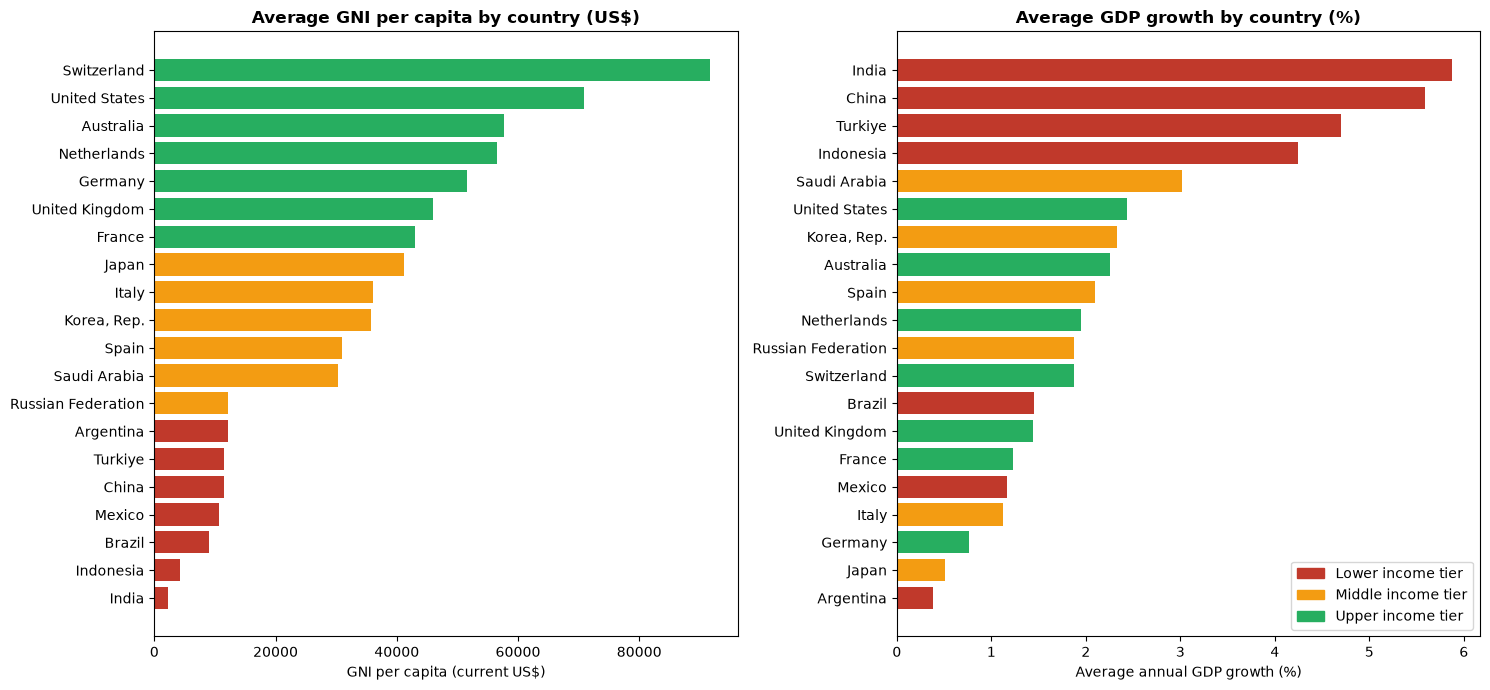

In [28]:
from matplotlib.patches import Patch

tier_colors = {'Lower': '#c0392b', 'Middle': '#f39c12', 'Upper': '#27ae60'}

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left chart: average GNI per capita by country
gni = tiers['GNI_Per_Capita'].sort_values()
axes[0].barh(gni.index, gni.values,
             color=[tier_colors[tiers.loc[c, 'Income_Tier']] for c in gni.index])
axes[0].set_title('Average GNI per capita by country (US$)', fontweight='bold')
axes[0].set_xlabel('GNI per capita (current US$)')

# Right chart: average GDP growth by country
growth = tiers['GDP_Growth_Pct'].sort_values()
axes[1].barh(growth.index, growth.values,
             color=[tier_colors[tiers.loc[c, 'Income_Tier']] for c in growth.index])
axes[1].set_title('Average GDP growth by country (%)', fontweight='bold')
axes[1].set_xlabel('Average annual GDP growth (%)')

legend_items = [Patch(color=col, label=name + ' income tier') for name, col in tier_colors.items()]
axes[1].legend(handles=legend_items, loc='lower right')

fig.tight_layout()
fig.savefig('../Visualizations/category_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## Q7 — Correlations Between Indicators

In [29]:
key_cols = ['GDP_Growth_Pct', 'GNI_Per_Capita', 'Inflation_Pct', 'Exports_Pct_GDP',
            'Imports_Pct_GDP', 'Life_Expectancy', 'Fertility_Rate', 'Under5_Mortality',
            'Population_Growth_Pct', 'Industry_Pct_GDP', 'Agriculture_Pct_GDP',
            'Capital_Formation_Pct_GDP', 'Mobile_Subs_Per100', 'Military_Exp_Pct_GDP']

corr = panel[key_cols].corr().round(2)

# Keep each pair once (upper triangle) and rank by strength
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top_pairs = pd.DataFrame({
    'Indicator 1': pairs.index.get_level_values(0),
    'Indicator 2': pairs.index.get_level_values(1),
    'Correlation': pairs.values
})
top_pairs['Strength'] = top_pairs['Correlation'].abs()
top_pairs = top_pairs.sort_values('Strength', ascending=False).drop(columns='Strength')

top_pairs.head(10)

,Indicator 1,Indicator 2,Correlation
46,Exports_Pct_GDP,Imports_Pct_GDP,0.98
108,Under5_Mortality,Agriculture_Pct_GDP,0.91
77,Life_Expectancy,Under5_Mortality,-0.81
80,Life_Expectancy,Agriculture_Pct_GDP,-0.77
19,GNI_Per_Capita,Life_Expectancy,0.72
24,GNI_Per_Capita,Agriculture_Pct_GDP,-0.69
137,Industry_Pct_GDP,Capital_Formation_Pct_GDP,0.63
21,GNI_Per_Capita,Under5_Mortality,-0.62
91,Fertility_Rate,Under5_Mortality,0.59
76,Life_Expectancy,Fertility_Rate,-0.59


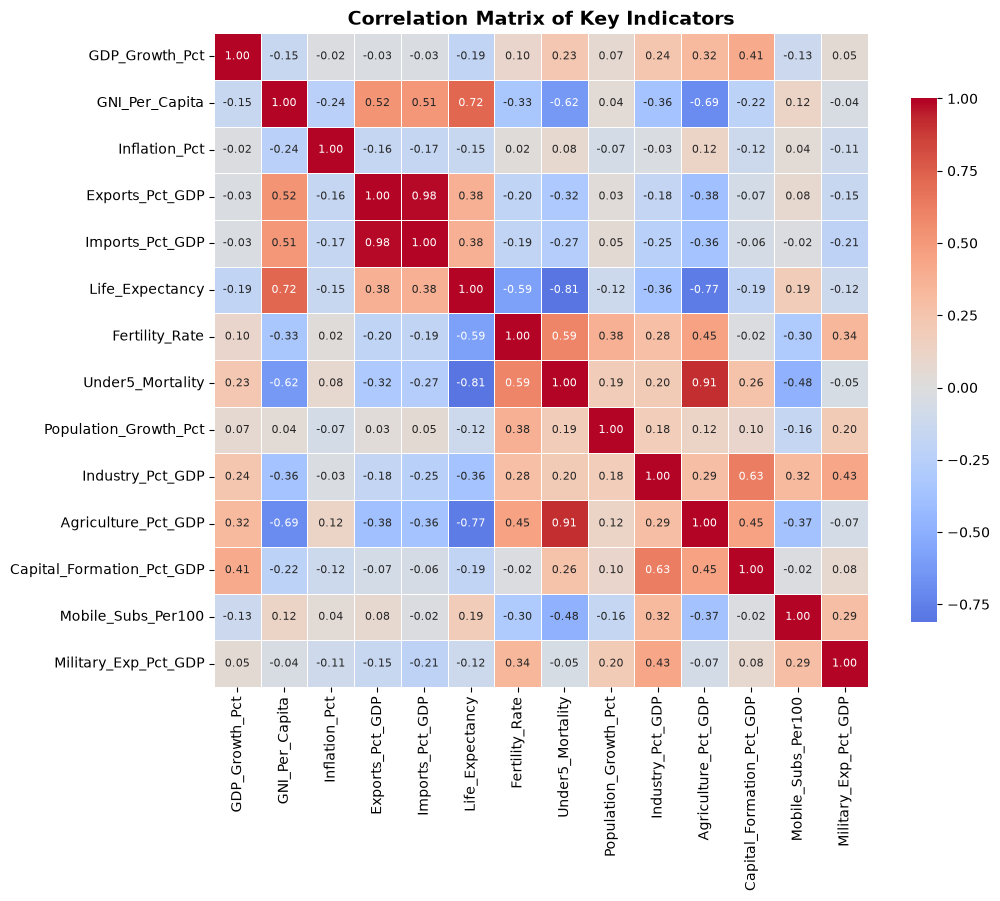

In [30]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 8}, ax=ax)
ax.set_title('Correlation Matrix of Key Indicators', fontsize=14, fontweight='bold')

fig.tight_layout()
fig.savefig('../Visualizations/correlation_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## Q8 — Key Findings

1. **Most country-years had positive growth.** Only 15.5% of the 200 country-years (31) were contractions, and almost all of them are from 2020.

2. **COVID-19 was the defining shock.** Average GDP growth fell from 1.79% in 2019 to -4.32% in 2020, then rebounded to +6.56% in 2021. Spain (-10.94%), the United Kingdom (-10.05%) and Argentina (-9.90%) fell the most in 2020. Only China (+2.34%) and Turkiye (+1.80%) still grew.

3. **Richer countries do not grow faster.** India (5.88%), China (5.59%) and Turkiye (4.70%) had the highest average growth, while Argentina (0.39%), Japan (0.51%) and Germany (0.76%) had the lowest. The Lower income tier grew 3.34% a year against 1.70% for the Upper tier, and the correlation between GNI per capita and growth is only -0.15.

4. **Inflation is extremely uneven.** Argentina averaged 70.47% (peaking at 207.61% in 2024) and Turkiye 35.37%, while every other country averaged under 9%. These two countries account for most of the 25 inflation outliers.

5. **Exports and imports move together.** Their correlation is 0.98. The Netherlands exports 85.33% of its GDP compared with only 11.42% for the United States.

6. **Income goes with health.** GNI per capita is positively correlated with life expectancy (0.72) and negatively with agriculture's share of GDP (-0.69). The Upper tier's life expectancy is 81.57 years against 74.33 for the Lower tier.

7. **Switzerland, the United States and Australia** have the highest average GNI per capita, while India and Indonesia have the lowest.

### Limitations
- Only 20 large economies are included, so the results do not represent all countries.
- Correlation shows association, not causation.
- Several social indicators (life expectancy, fertility, child mortality, military spending, mobile subscriptions) are missing for the most recent years, because the World Bank publishes them with a delay.

## Conclusion
The data shows an economy that was hit hard in 2020, recovered strongly in 2021 and settled near 2% to 2.5% average growth. Lower-income economies grew faster than richer ones, while higher income goes with better health outcomes and lower inflation. Extreme inflation in Argentina and Turkiye is the main outlier in the data.